# Complete EDA for `Market.csv`

**Libraries:** NumPy, Pandas, Matplotlib, Seaborn  
**Purpose:** Explore and validate the market-index data, then prepare it safely for a future linear-regression model.

> **Important for this dataset:** it contains 14 different indices. Begin with one index (the example below defaults to `NSEI`) or build a deliberately designed pooled model. Price levels from different indices are not directly comparable. The workflow assumes the eventual forecasting task is **predicting the next observed trading session's `Close`**. Change the target logic if your objective is different.

Run the notebook from the folder containing `Market.csv.zip` or `Market.csv`.

## Step 1 — Import libraries

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

RANDOM_STATE = 42

## Step 2 — Load the CSV (including from the uploaded ZIP)

In [2]:
zip_path = Path("Market.csv.zip")
csv_path = Path("Market.csv")

if zip_path.exists():
    with zipfile.ZipFile(zip_path) as zf:
        csv_members = [name for name in zf.namelist() if name.lower().endswith(".csv")]
        if not csv_members:
            raise FileNotFoundError("No CSV file was found inside Market.csv.zip")
        with zf.open(csv_members[0]) as f:
            df = pd.read_csv(f, low_memory=False)
elif csv_path.exists():
    df = pd.read_csv(csv_path, low_memory=False)
else:
    raise FileNotFoundError("Place Market.csv.zip or Market.csv in the notebook's working folder.")

df.columns = df.columns.str.strip()
# Rename this column only to avoid a space in the feature name.
df = df.rename(columns={"Adj Close": "Adj_Close"})

print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (112457, 8)


,Index,Date,Open,High,Low,Close,Adj_Close,Volume
0,NYA,12/31/1965,528.690002,528.690002,528.690002,528.690002,528.690002,0.0
1,NYA,1/3/1966,527.210022,527.210022,527.210022,527.210022,527.210022,0.0
2,NYA,1/4/1966,527.840027,527.840027,527.840027,527.840027,527.840027,0.0
3,NYA,1/5/1966,531.119995,531.119995,531.119995,531.119995,531.119995,0.0
4,NYA,1/6/1966,532.070007,532.070007,532.070007,532.070007,532.070007,0.0


## Step 3 — Understand the structure and data types

In [8]:
print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nNumeric summary:")
display(df.describe(include="number").T)
print("\nCategorical summary:")
display(df.describe(include="object").T)

Shape: (112457, 8)

Column names: ['Index', 'Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 112457 entries, 0 to 112456
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Index      112457 non-null  str           
 1   Date       112457 non-null  datetime64[us]
 2   Open       110253 non-null  float64       
 3   High       110252 non-null  float64       
 4   Low        110251 non-null  float64       
 5   Close      110250 non-null  float64       
 6   Adj_Close  110244 non-null  float64       
 7   Volume     110253 non-null  float64       
dtypes: datetime64[us](1), float64(6), str(1)
memory usage: 7.4 MB

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Open,110253.0,7.658562e+03,9.011456e+03,54.869999,1855.060059,5194.399902,1.013430e+04,6.877506e+04
High,110252.0,7.704538e+03,9.066605e+03,54.869999,1864.687470,5226.750000,1.020783e+04,6.940375e+04
Low,110251.0,7.608130e+03,8.954537e+03,54.869999,1844.015015,5154.299805,1.006037e+04,6.851699e+04
Close,110250.0,7.657741e+03,9.011556e+03,54.869999,1855.347473,5194.889892,1.013487e+04,6.877506e+04
Adj_Close,110244.0,7.657983e+03,9.011724e+03,54.869999,1855.057556,5195.699951,1.013551e+04,6.877506e+04
Volume,110253.0,1.273975e+09,4.315783e+09,0.000000,0.000000,432900.000000,1.734314e+08,9.440374e+10



Categorical summary:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_16740\1465344762.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Index,112457,14,N225,14500


## Step 4 — Convert dates and sort correctly

In [9]:
# Source dates use month/day/year text, for example 12/31/1965.
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")

print("Unparsed dates:", df["Date"].isna().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of indices:", df["Index"].nunique())
print(df["Index"].value_counts())

df = df.dropna(subset=["Date"]).sort_values(["Index", "Date"]).reset_index(drop=True)
display(df.head())

Unparsed dates: 0
Date range: 1965-01-05 00:00:00 to 2021-06-03 00:00:00
Number of indices: 14
Index
N225         14500
NYA          13948
IXIC         12690
GSPTSE       10776
HSI           8750
GDAXI         8606
SSMI          7830
KS11          6181
TWII          6010
000001.SS     5963
399001.SZ     5928
N100          5507
NSEI          3381
J203.JO       2387
Name: count, dtype: int64


,Index,Date,Open,High,Low,Close,Adj_Close,Volume
0,000001.SS,1997-07-02,1255.909058,1261.571045,1147.331055,1199.061035,1199.061035,0.0
1,000001.SS,1997-07-03,1194.676025,1194.676025,1149.939941,1150.623047,1150.623047,0.0
2,000001.SS,1997-07-04,1138.921021,1163.249023,1124.776001,1159.342041,1159.342041,0.0
3,000001.SS,1997-07-07,1161.707031,1163.447021,1085.572021,1096.818970,1096.818970,0.0
4,000001.SS,1997-07-08,1092.798950,1115.432983,1066.043945,1109.666016,1109.666016,0.0


## Step 5 — Check duplicate rows and duplicate index-date keys

In [10]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Index-Date pairs:", df.duplicated(subset=["Index", "Date"]).sum())

# If duplicates exist, inspect them before deciding whether to remove anything.
duplicate_keys = df[df.duplicated(subset=["Index", "Date"], keep=False)].sort_values(["Index", "Date"])
display(duplicate_keys.head(20))

Exact duplicate rows: 0
Duplicate Index-Date pairs: 0


,Index,Date,Open,High,Low,Close,Adj_Close,Volume


## Step 6 — Quantify missing values

,missing_count,missing_percent
Adj_Close,2213,1.97
High,2205,1.96
Low,2206,1.96
Open,2204,1.96
Close,2207,1.96
Volume,2204,1.96
Index,0,0.00
Date,0,0.00


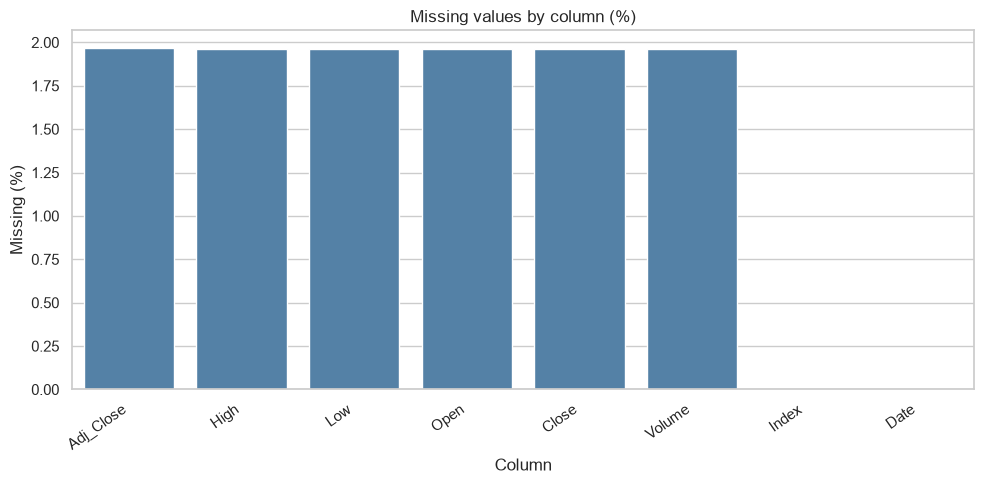

Rows where all six numeric measurements are missing: 2204
Rows with only some measurements missing: 15


In [11]:
numeric_cols = ["Open", "High", "Low", "Close", "Adj_Close", "Volume"]
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)

plt.figure(figsize=(10, 5))
sns.barplot(data=missing_summary.reset_index(names="column"), x="column", y="missing_percent", color="steelblue")
plt.title("Missing values by column (%)")
plt.ylabel("Missing (%)")
plt.xlabel("Column")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Count rows where all market measurements are absent versus partially missing.
all_measurements_missing = df[numeric_cols].isna().all(axis=1).sum()
partially_missing = (df[numeric_cols].isna().any(axis=1) & ~df[numeric_cols].isna().all(axis=1)).sum()
print("Rows where all six numeric measurements are missing:", all_measurements_missing)
print("Rows with only some measurements missing:", partially_missing)

## Step 7 — Inspect missingness patterns and decide how to handle them

In [12]:
missing_pattern = df[numeric_cols].isna().sum(axis=1).value_counts().sort_index()
display(missing_pattern.rename_axis("number_of_missing_numeric_fields").to_frame("row_count"))

# Keep original df intact for auditing. This working copy removes only rows with no market measurements at all.
df_eda = df.dropna(subset=numeric_cols, how="all").copy()
print("Rows after removing fully empty market records:", len(df_eda))
print("Rows removed:", len(df) - len(df_eda))

# Do not automatically forward-fill prices across market holidays or fill missing targets.
# For a simple first model, rows with missing required features/target can be dropped at model-prep time.

,row_count
number_of_missing_numeric_fields,
0,110238
1,15
6,2204


Rows after removing fully empty market records: 110253
Rows removed: 2204


## Step 8 — Check zero volume and other suspicious values

In [13]:
zero_volume_count = df_eda["Volume"].eq(0).sum()
print(f"Zero-volume rows: {zero_volume_count:,} ({zero_volume_count / len(df_eda) * 100:.2f}%)")
print("Negative-volume rows:", df_eda["Volume"].lt(0).sum())

zero_volume_by_index = (df_eda.assign(zero_volume=df_eda["Volume"].eq(0))
                         .groupby("Index")["zero_volume"].mean().mul(100).sort_values(ascending=False))
display(zero_volume_by_index.round(2).rename("zero_volume_percent").to_frame())

# A zero may mean unavailable/non-reported volume for a given index or historical period.
# Investigate its meaning before treating zero as missing or deleting these rows.

Zero-volume rows: 42,093 (38.18%)
Negative-volume rows: 0


,zero_volume_percent
Index,
J203.JO,100.00
N225,66.59
NYA,63.33
HSI,42.42
SSMI,39.62
NSEI,39.45
GDAXI,35.25
N100,30.27
399001.SZ,27.26


## Step 9 — Validate OHLC relationships

In [14]:
ohlc_cols = ["Open", "High", "Low", "Close"]
complete_ohlc = df_eda[ohlc_cols].notna().all(axis=1)
max_open_close = df_eda[["Open", "Close"]].max(axis=1)
min_open_close = df_eda[["Open", "Close"]].min(axis=1)

bad_ohlc_mask = complete_ohlc & (
    (df_eda["High"] < df_eda["Low"]) |
    (df_eda["High"] < max_open_close) |
    (df_eda["Low"] > min_open_close)
)
bad_ohlc = df_eda.loc[bad_ohlc_mask, ["Index", "Date"] + ohlc_cols]
print("Rows violating at least one OHLC relationship:", len(bad_ohlc))
display(bad_ohlc)

# Do not silently correct suspicious prices. Verify against the original data source first.

Rows violating at least one OHLC relationship: 1


,Index,Date,Open,High,Low,Close
85521,NYA,1969-06-30,5722.359985,572.359985,572.359985,572.359985


## Step 10 — Summarize the history for every index

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16740\486245413.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(index_summary.round(2))


,rows,first_date,last_date,missing_close,mean_close,min_close,max_close,zero_volume_rows
Index,,,,,,,,
NYA,13947,1965-12-31,2021-05-28,3,4453.03,347.77,16590.43,8832
N225,13874,1965-01-05,2021-06-03,0,12849.16,1020.49,38915.87,9239
IXIC,12690,1971-02-05,2021-05-28,0,1984.91,54.87,14138.78,3457
GSPTSE,10526,1979-06-29,2021-05-31,0,8090.07,1346.40,19852.20,1343
HSI,8492,1986-12-31,2021-05-31,0,15200.61,1894.90,33154.12,3602
GDAXI,8438,1987-12-30,2021-05-31,0,5914.85,936.00,15519.98,2974
SSMI,7671,1990-11-09,2021-05-28,0,6409.73,1287.60,11426.15,3039
KS11,6029,1996-12-11,2021-06-01,0,1489.15,280.00,3249.30,0
TWII,5869,1997-07-02,2021-05-31,0,8028.87,3446.26,17595.90,1353


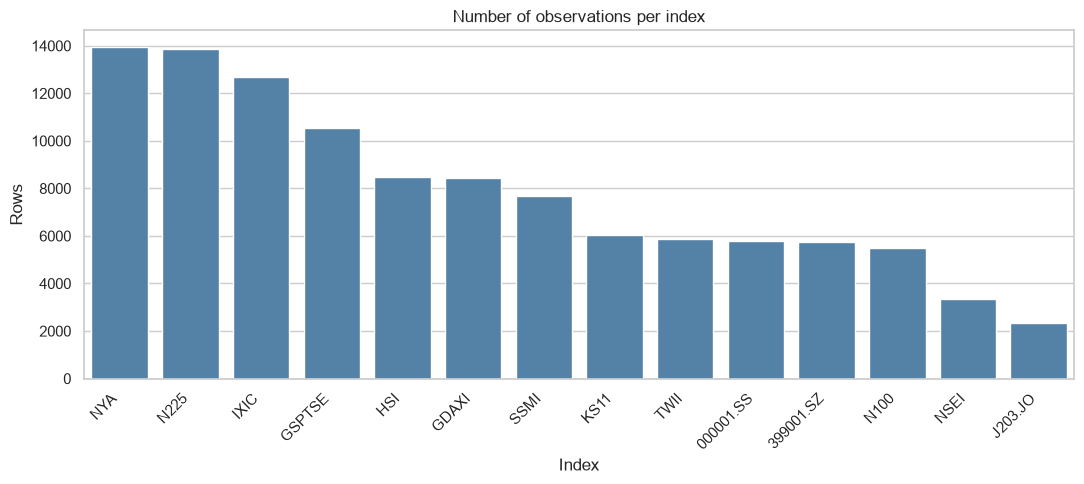

In [15]:
index_summary = (df_eda.groupby("Index")
    .agg(
        rows=("Date", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        missing_close=("Close", lambda s: s.isna().sum()),
        mean_close=("Close", "mean"),
        min_close=("Close", "min"),
        max_close=("Close", "max"),
        zero_volume_rows=("Volume", lambda s: s.eq(0).sum()),
    )
    .sort_values("rows", ascending=False))
display(index_summary.round(2))

plt.figure(figsize=(11, 5))
sns.barplot(data=index_summary.reset_index(), x="Index", y="rows", color="steelblue")
plt.title("Number of observations per index")
plt.xlabel("Index")
plt.ylabel("Rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 11 — Plot price trends without comparing raw index levels

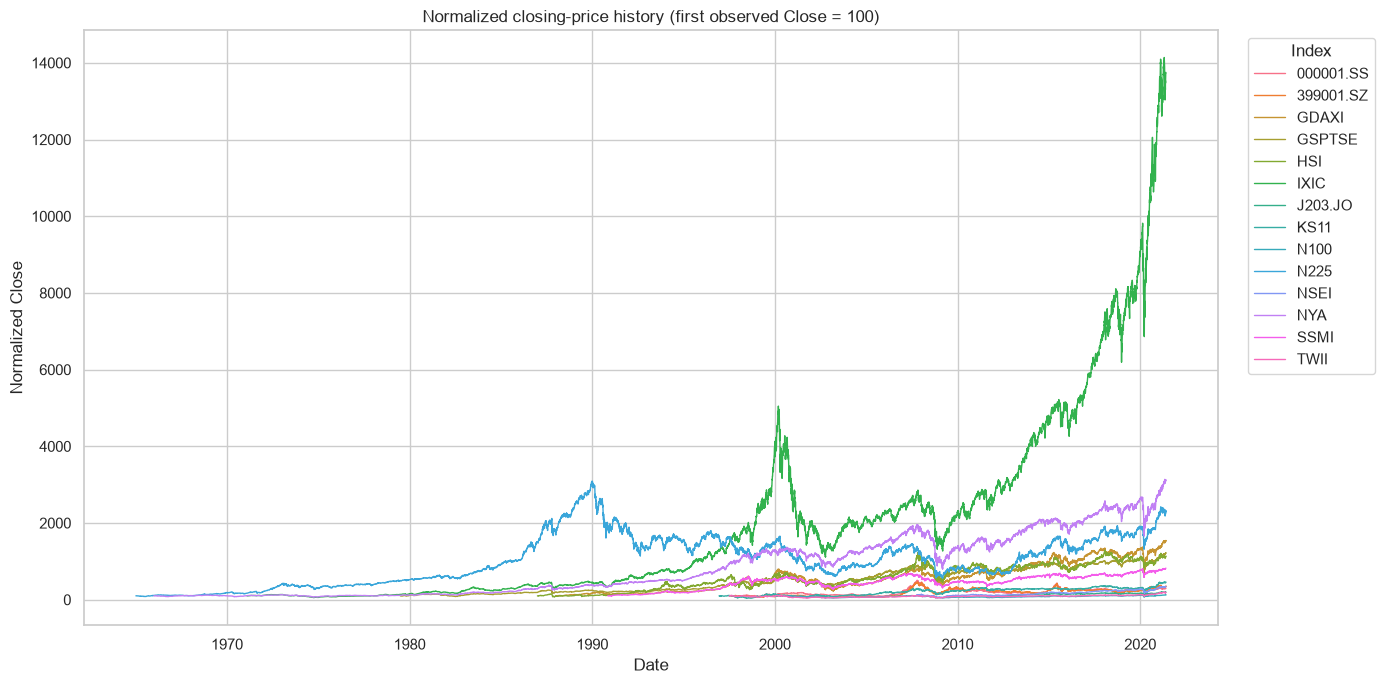

In [16]:
# Index price scales differ. Normalize each index to 100 at its first valid Close.
trend_df = df_eda.dropna(subset=["Close"]).sort_values(["Index", "Date"]).copy()
trend_df["Normalized_Close"] = trend_df["Close"] / trend_df.groupby("Index")["Close"].transform("first") * 100

plt.figure(figsize=(14, 7))
sns.lineplot(data=trend_df, x="Date", y="Normalized_Close", hue="Index", linewidth=1)
plt.title("Normalized closing-price history (first observed Close = 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Close")
plt.legend(title="Index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 12 — Choose one index for focused EDA

In [17]:
# Default to NSEI (Nifty 50). Change this to any value printed by df['Index'].unique().
selected_index = "NSEI"
if selected_index not in df_eda["Index"].unique():
    selected_index = df_eda["Index"].value_counts().index[0]

one = (df_eda[df_eda["Index"] == selected_index]
       .sort_values("Date")
       .copy())
print("Selected index:", selected_index)
print("Rows:", len(one), "| Date range:", one["Date"].min(), "to", one["Date"].max())
display(one.head())

Selected index: NSEI
Rows: 3346 | Date range: 2007-09-17 00:00:00 to 2021-05-31 00:00:00


,Index,Date,Open,High,Low,Close,Adj_Close,Volume
81288,NSEI,2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,4494.649902,0.0
81289,NSEI,2007-09-18,4494.100098,4551.799805,4481.549805,4546.200195,4546.200195,0.0
81290,NSEI,2007-09-19,4550.250000,4739.000000,4550.250000,4732.350098,4732.350098,0.0
81291,NSEI,2007-09-20,4734.850098,4760.850098,4721.149902,4747.549805,4747.549805,0.0
81292,NSEI,2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,4837.549805,0.0


## Step 13 — Analyze distributions and skewness

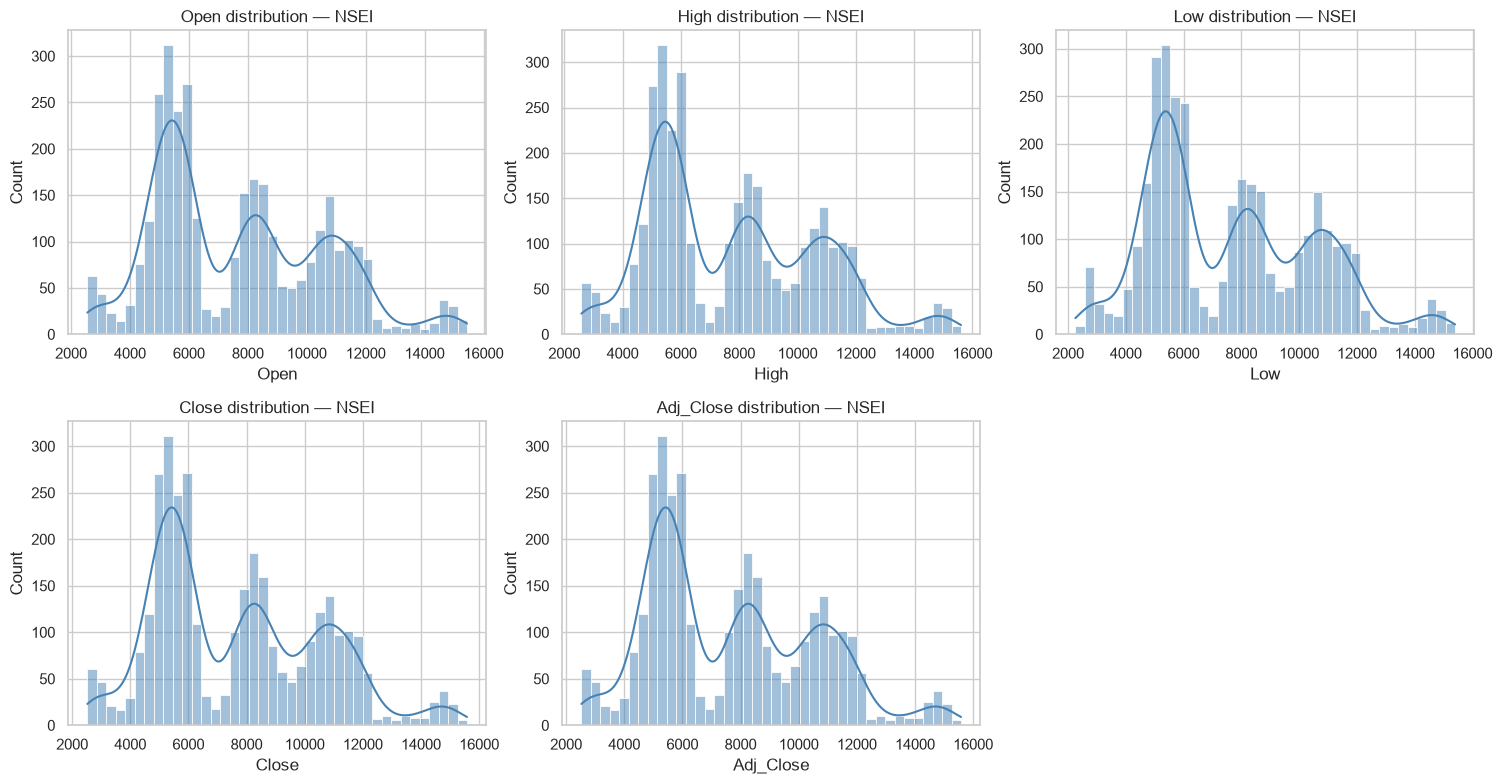

,skewness
Volume,1.775004
High,0.526814
Adj_Close,0.518651
Close,0.518651
Open,0.518517
Low,0.507271


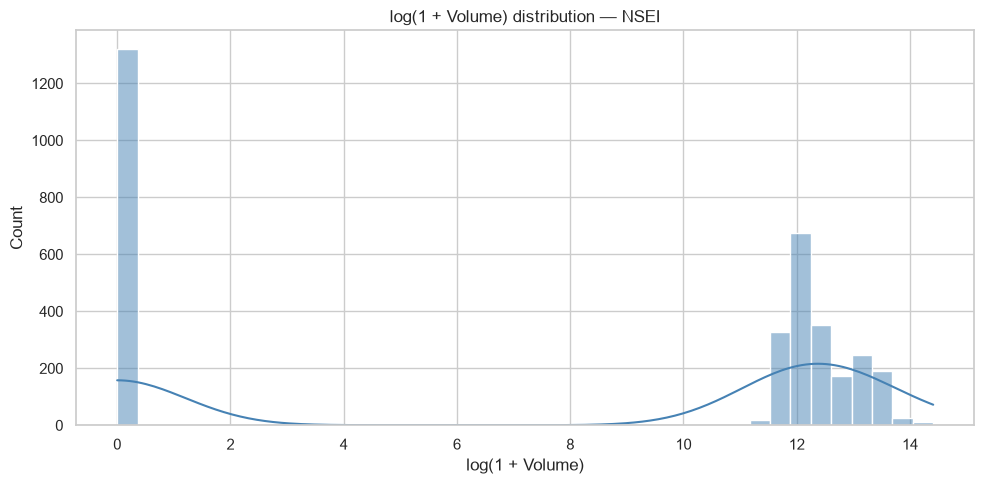

In [18]:
price_cols = ["Open", "High", "Low", "Close", "Adj_Close"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(price_cols, axes.flat):
    sns.histplot(data=one, x=col, bins=40, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} distribution — {selected_index}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

skewness = one[price_cols + ["Volume"]].skew(numeric_only=True).sort_values(ascending=False)
display(skewness.rename("skewness").to_frame())

# Volume is often highly skewed; log1p works with zero values.
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(one["Volume"].dropna()), bins=40, kde=True, color="steelblue")
plt.title(f"log(1 + Volume) distribution — {selected_index}")
plt.xlabel("log(1 + Volume)")
plt.tight_layout()
plt.show()

## Step 14 — Use boxplots and IQR to flag possible outliers

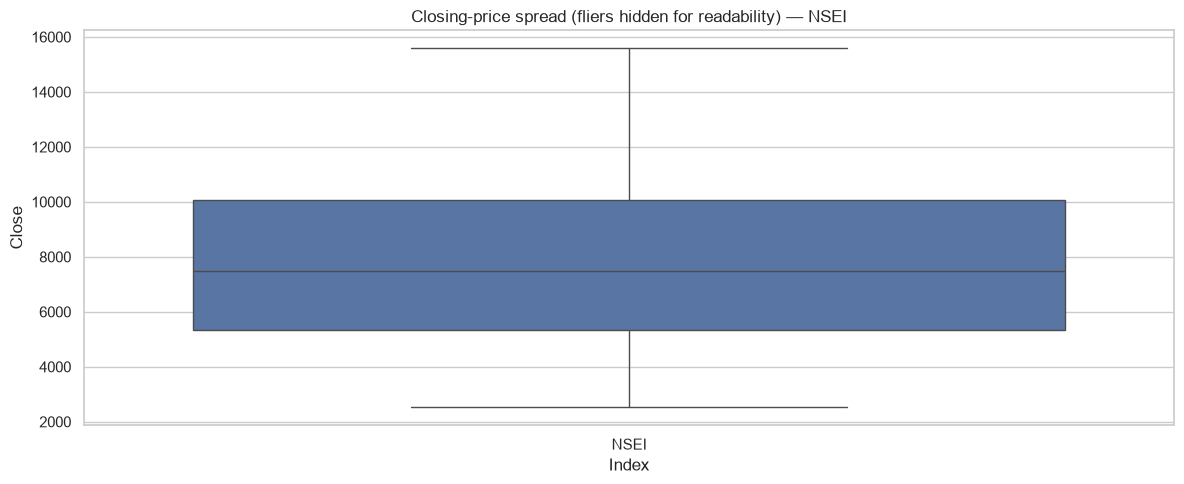

IQR bounds: -1796.543212499998 to 17197.0056155
Close values flagged for review: 0


,Index,Date,Close


In [19]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=one, x="Index", y="Close", showfliers=False)
plt.title(f"Closing-price spread (fliers hidden for readability) — {selected_index}")
plt.tight_layout()
plt.show()

# IQR flags are for review, not automatic deletion: legitimate market movements may be extreme.
close = one["Close"].dropna()
q1, q3 = close.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
iqr_outliers = one.loc[one["Close"].notna() & ((one["Close"] < lower_bound) | (one["Close"] > upper_bound)),
                       ["Index", "Date", "Close"]]
print("IQR bounds:", lower_bound, "to", upper_bound)
print("Close values flagged for review:", len(iqr_outliers))
display(iqr_outliers.head(20))

## Step 15 — Explore daily returns and volatility

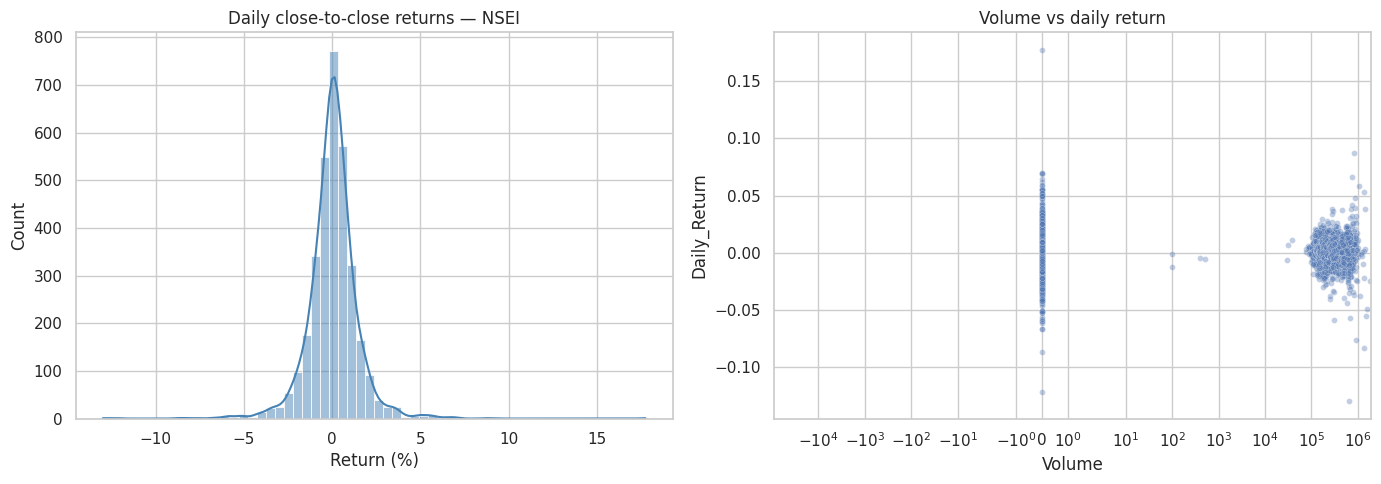

Daily return summary (%):


,Daily_Return_pct
count,3345.000000
mean,0.047415
std,1.431102
min,-12.980466
25%,-0.582354
50%,0.066500
75%,0.699756
max,17.744066


In [15]:
one["Daily_Return"] = one["Close"].pct_change(fill_method=None)
one["Intraday_Return"] = (one["Close"] - one["Open"]) / one["Open"]
one["Daily_Range"] = one["High"] - one["Low"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(one["Daily_Return"].dropna() * 100, bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"Daily close-to-close returns — {selected_index}")
axes[0].set_xlabel("Return (%)")
sns.scatterplot(data=one, x="Volume", y="Daily_Return", alpha=0.35, s=18, ax=axes[1])
axes[1].set_title("Volume vs daily return")
axes[1].set_xscale("symlog")
plt.tight_layout()
plt.show()

print("Daily return summary (%):")
display((one["Daily_Return"] * 100).describe().to_frame("Daily_Return_pct"))

## Step 16 — Correlation analysis (for one index, not the pooled dataset)

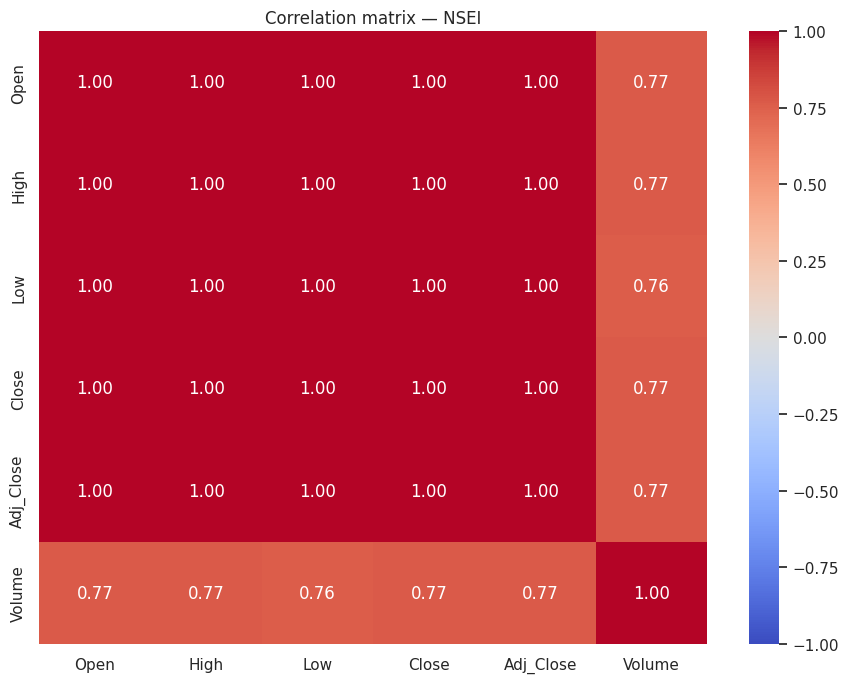

In [16]:
corr_cols = ["Open", "High", "Low", "Close", "Adj_Close", "Volume"]
corr = one[corr_cols].corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title(f"Correlation matrix — {selected_index}")
plt.tight_layout()
plt.show()

# Correlation is descriptive, not causal. Adj_Close and Close are almost duplicates here;
# do not use Adj_Close to predict same-day Close.

## Step 17 — Inspect pairwise relationships

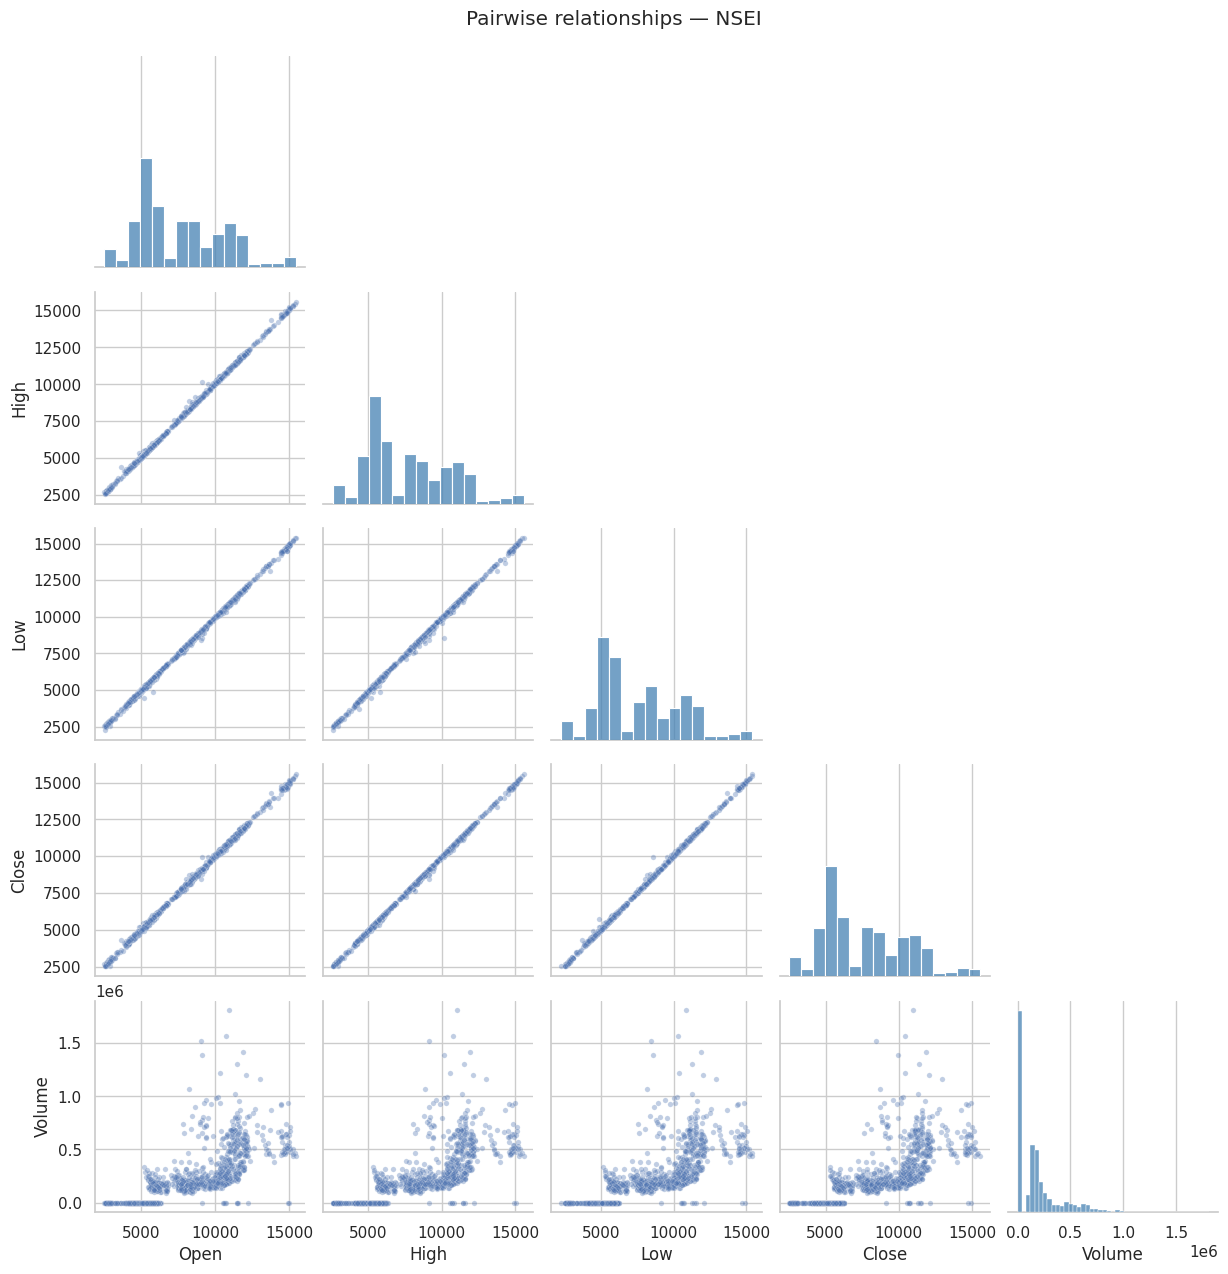

In [17]:
pair_cols = ["Open", "High", "Low", "Close", "Volume"]
pair_data = one[pair_cols].dropna()
if len(pair_data) > 1500:
    pair_data = pair_data.sample(1500, random_state=RANDOM_STATE)
sns.pairplot(pair_data, corner=True, diag_kind="hist", diag_kws={"color": "steelblue"}, plot_kws={"alpha": 0.35, "s": 15})
plt.suptitle(f"Pairwise relationships — {selected_index}", y=1.02)
plt.show()

## Step 18 — Review correlations and linear-regression caveats

In [18]:
# A compact table of correlations with same-day Close.
close_corr = one[corr_cols].corr(numeric_only=True)["Close"].sort_values(ascending=False)
display(close_corr.rename("correlation_with_same_day_Close").to_frame())

print("Important interpretation points:")
print("1. Open/High/Low/Close are mathematically related, so correlations near 1 are expected.")
print("2. Adj_Close is nearly identical to Close in this file; exclude it when Close is the target.")
print("3. Price levels often trend over time, so a high correlation does not guarantee forecast skill.")
print("4. Avoid a random train/test split for a time-ordered forecasting problem.")

,correlation_with_same_day_Close
Adj_Close,1.000000
Close,1.000000
High,0.999801
Low,0.999774
Open,0.999574
Volume,0.767871


Important interpretation points:
1. Open/High/Low/Close are mathematically related, so correlations near 1 are expected.
2. Adj_Close is nearly identical to Close in this file; exclude it when Close is the target.
3. Price levels often trend over time, so a high correlation does not guarantee forecast skill.
4. Avoid a random train/test split for a time-ordered forecasting problem.


## Step 19 — Create next-session target and lag features

In [19]:
# Forecasting setup: after session t closes, use data available through t to predict Close at t+1.
# Shift is applied within this one index only; the next row means the next observed session in this file.
model_data = one.sort_values("Date").copy()

base_features = ["Open", "High", "Low", "Close", "Volume"]
for col in base_features:
    model_data[f"{col}_lag1"] = model_data[col].shift(1)
    model_data[f"{col}_lag2"] = model_data[col].shift(2)

model_data["Target_Close_Next_Session"] = model_data["Close"].shift(-1)
model_data["Return_through_t"] = model_data["Close"].pct_change(fill_method=None)
model_data["RollingMean_Close_5"] = model_data["Close"].rolling(window=5, min_periods=5).mean()

# Include current-session features plus lagged values; Adj_Close is deliberately excluded.
feature_cols = base_features + [f"{col}_lag{lag}" for col in base_features for lag in (1, 2)] + ["Return_through_t", "RollingMean_Close_5"]
target_col = "Target_Close_Next_Session"

model_ready = model_data[["Date"] + feature_cols + [target_col]].replace([np.inf, -np.inf], np.nan)
model_ready = model_ready.dropna(subset=feature_cols + [target_col]).copy()
print("Rows available for modelling after lags/missing-value removal:", len(model_ready))
display(model_ready.head())

Rows available for modelling after lags/missing-value removal: 3341


,Date,Open,High,Low,Close,Volume,Open_lag1,Open_lag2,High_lag1,High_lag2,Low_lag1,Low_lag2,Close_lag1,Close_lag2,Volume_lag1,Volume_lag2,Return_through_t,RollingMean_Close_5,Target_Close_Next_Session
81292,2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,0.0,4734.850098,4550.250000,4760.850098,4739.000000,4721.149902,4550.250000,4747.549805,4732.350098,0.0,0.0,0.018957,4671.659961,4932.200195
81293,2007-09-24,4837.149902,4941.149902,4837.149902,4932.200195,0.0,4752.950195,4734.850098,4855.700195,4760.850098,4733.700195,4721.149902,4837.549805,4747.549805,0.0,0.0,0.019566,4759.170020,4938.850098
81294,2007-09-25,4939.100098,4953.899902,4878.149902,4938.850098,0.0,4837.149902,4752.950195,4941.149902,4855.700195,4837.149902,4733.700195,4932.200195,4837.549805,0.0,0.0,0.001348,4837.700000,4940.500000
81295,2007-09-26,4937.600098,4980.850098,4930.350098,4940.500000,0.0,4939.100098,4837.149902,4953.899902,4941.149902,4878.149902,4837.149902,4938.850098,4932.200195,0.0,0.0,0.000334,4879.329981,5000.549805
81296,2007-09-27,4942.700195,5016.399902,4942.700195,5000.549805,0.0,4937.600098,4939.100098,4980.850098,4953.899902,4930.350098,4878.149902,4940.500000,4938.850098,0.0,0.0,0.012155,4929.929981,5021.350098


## Step 20 — Split chronologically (no shuffling)

In [20]:
# Example 70% train / 15% validation / 15% test, in chronological order.
model_ready = model_ready.sort_values("Date").reset_index(drop=True)
n = len(model_ready)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train_df = model_ready.iloc[:train_end].copy()
valid_df = model_ready.iloc[train_end:valid_end].copy()
test_df = model_ready.iloc[valid_end:].copy()

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_valid, y_valid = valid_df[feature_cols], valid_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print("Train dates:", train_df["Date"].min(), "to", train_df["Date"].max(), "rows:", len(train_df))
print("Validation dates:", valid_df["Date"].min(), "to", valid_df["Date"].max(), "rows:", len(valid_df))
print("Test dates:", test_df["Date"].min(), "to", test_df["Date"].max(), "rows:", len(test_df))

Train dates: 2007-09-21 00:00:00 to 2017-04-27 00:00:00 rows: 2338
Validation dates: 2017-04-28 00:00:00 to 2019-05-14 00:00:00 rows: 501
Test dates: 2019-05-15 00:00:00 to 2021-05-28 00:00:00 rows: 502


## Step 21 — Final checklist before fitting linear regression

- [ ] Select the index you actually want to forecast; do not mix raw price levels across all indices without a plan.
- [ ] Confirm and investigate invalid OHLC records (this file contains at least one suspicious price record).
- [ ] Decide whether zero volume means true zero or unavailable data for each index and period.
- [ ] Keep missing target values out of training; avoid filling future targets.
- [ ] Do not use `Adj_Close` as a feature when predicting `Close`.
- [ ] For next-session forecasts, use lagged features and chronological validation/test splits.
- [ ] Evaluate MAE, RMSE and R² on the held-out test period; compare against a naive baseline such as predicting next Close = current Close.
- [ ] Inspect residuals after fitting; linear regression assumptions should be checked on the model errors, not only on raw feature correlations.

**Interpretation reminder:** EDA helps assess data quality and relationships, but it does not establish that a linear model will predict market prices accurately.